In [1]:
from src.io_utils import load_csv_to_dataframe
from src.schemas import PathConfig

import pandas as pd
import matplotlib.pyplot as plt
config = PathConfig()
df = load_csv_to_dataframe(config.input_dir / "creditcard.csv")

## EDA

### Datasetets storlek 
Datasetet innehåller 284 807 observationer och 31 ursprungliga variabler. Variablerna består av Time, Amount, målvariabeln Class samt de anonymiserade variablerna V1–V28.
### Datatyper och generell information
Samtliga variabler i datasetet är numeriska. Detta innebär att datan i stort sett är direkt användbar för vidare analys och modellering utan behov av kodning av kategoriska variabler.

### Saknade värden
Inga saknade värden identifierades i datasetet. Det krävs därför ingen imputering eller annan behandling av null-värden innan fortsatt analys.

### Deskriptiv statistik
Den deskriptiva statistiken visar stor variation mellan variablernas skalor. Framför allt varierar Amount kraftigt, medan V1–V28 är transformerade variabler med värden centrerade kring noll.

In [2]:
def basic_eda(df: pd.DataFrame) -> None:
    print("\n--- SHAPE ---")
    print(df.shape)

    print("\n--- INFO ---")
    df.info()

    print("\n--- SAKNADE VÄRDEN ---")
    print(df.isnull().sum())

    print("\n--- DUBLETTER ---")
    print(df.duplicated().sum())

    print("\n--- KLASSFÖRDELNING ---")
    print(df["Class"].value_counts())

    print("\n--- KLASSFÖRDELNING I PROCENT (%) ---")
    print(df["Class"].value_counts(normalize=True) * 100)

    print("\n--- DESKRIPTIV STATISTIK ---")
    print(df.describe())

    print("\n--- DATATYPER ---")
    print(df.dtypes)

basic_eda(df)


--- SHAPE ---
(284807, 31)

--- INFO ---
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 no

### Klassfördelning
Datasetet är kraftigt obalanserat. Klass 0, som representerar normala transaktioner, utgör nästan hela datasetet medan klass 1, bedrägliga transaktioner, endast utgör cirka 0,17 %. Detta är viktigt att ta hänsyn till vid senare modellutvärdering.

### Klassfördelning i diagram
Diagrammet visar tydligt den stora obalansen mellan klasserna. Den bedrägliga klassen är så liten i förhållande till den normala klassen att den nästan inte syns i ett vanligt stapeldiagram.

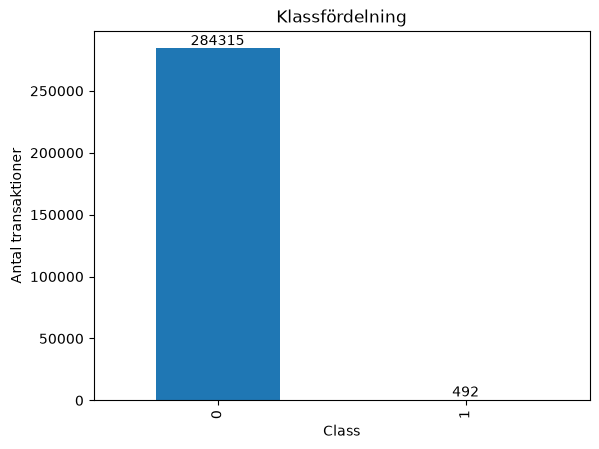

In [3]:
def plot_class_distribution(df: pd.DataFrame) -> None:
    counts = df["Class"].value_counts()

    ax = counts.plot(kind="bar")

    plt.title("Klassfördelning")
    plt.xlabel("Class")
    plt.ylabel("Antal transaktioner")

    for container in ax.containers:
        ax.bar_label(container)

    plt.show()

plot_class_distribution(df)

### Fördelning av transaktionsbelopp
Fördelningen av Amount är tydligt högerskev. Majoriteten av transaktionerna har relativt låga belopp, medan ett mindre antal transaktioner har mycket höga belopp.

### Amount per klass
Bedrägliga transaktioner har i genomsnitt ett högre transaktionsbelopp än normala transaktioner. Samtidigt förekommer de högsta enskilda beloppen bland normala transaktioner, vilket visar att höga belopp i sig inte är tillräckligt för att identifiera bedrägeri.

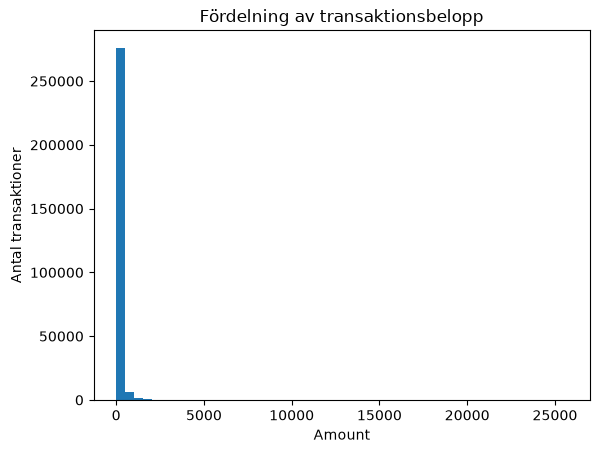

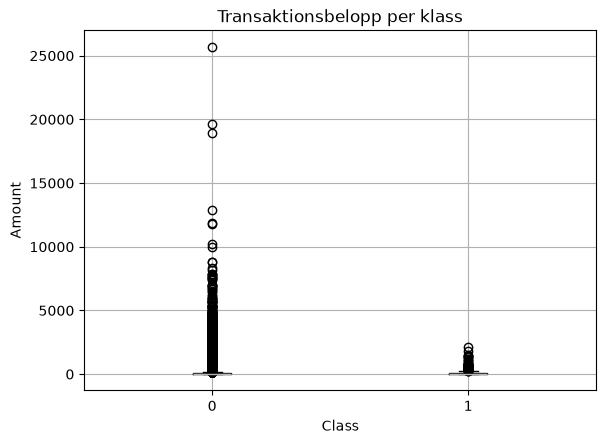


--- Antal PER KLASS ---
          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


In [4]:
def plot_amount_distribution(df: pd.DataFrame) -> None:
    plt.hist(df["Amount"], bins=50)

    plt.title("Fördelning av transaktionsbelopp")
    plt.xlabel("Amount")
    plt.ylabel("Antal transaktioner")
    plt.show()


def plot_amount_by_class(df: pd.DataFrame) -> None:
    df.boxplot(column="Amount", by="Class")

    plt.title("Transaktionsbelopp per klass")
    plt.suptitle("")
    plt.xlabel("Class")
    plt.ylabel("Amount")
    plt.show()

def amount_by_class(df: pd.DataFrame) -> None:
    print("\n--- Antal PER KLASS ---")
    print(
        df.groupby("Class")["Amount"].describe()
    )    

plot_amount_distribution(df)
plot_amount_by_class(df)
amount_by_class(df)

### Transaktioner över tid
Time representerar antal sekunder sedan den första registrerade transaktionen i datasetet. För att göra resultatet mer lättolkat omvandlades tiden till timmar. Diagrammet visar att transaktionsaktiviteten varierar över den cirka två dagar långa perioden.

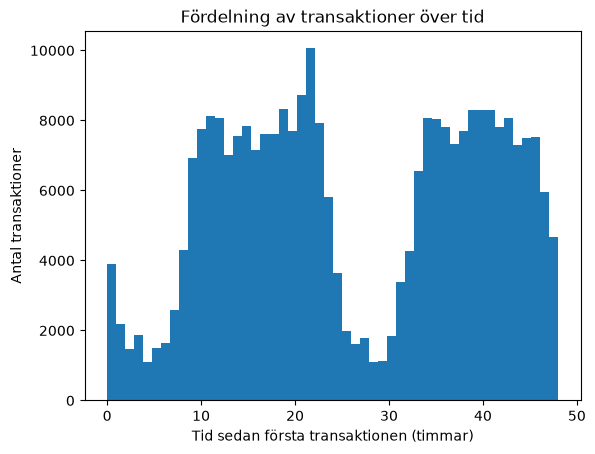

In [5]:
def plot_time_distribution(df: pd.DataFrame) -> None:
    df["Time_hours"] = df["Time"] / 3600

    plt.hist(df["Time_hours"], bins=50)

    plt.title("Fördelning av transaktioner över tid")
    plt.xlabel("Tid sedan första transaktionen (timmar)")
    plt.ylabel("Antal transaktioner")

    plt.show()

plot_time_distribution(df)

### Dubbletter
Totalt identifierades 1 081 exakta dubbletter. Av dessa tillhörde 1 062 klass 0 och 19 klass 1. Efter att dubbletterna tagits bort återstod 283 726 observationer.

In [6]:
duplicate_rows = df[df.duplicated()]

print("Antal dubbletter:", duplicate_rows.shape[0])
print("\nDubbletter per klass:")
print(duplicate_rows["Class"].value_counts())

df_clean = df.drop_duplicates().copy()

print("\nFöre:", df.shape)
print("Efter:", df_clean.shape)

print("Före:")
print(df["Class"].value_counts())

print("\nEfter:")
print(df_clean["Class"].value_counts())



Antal dubbletter: 1081

Dubbletter per klass:
Class
0    1062
1      19
Name: count, dtype: int64

Före: (284807, 32)
Efter: (283726, 32)
Före:
Class
0    284315
1       492
Name: count, dtype: int64

Efter:
Class
0    283253
1       473
Name: count, dtype: int64


### Slutsats från EDA
EDA:n visar att datasetet är komplett och huvudsakligen numeriskt, men mycket kraftigt obalanserat. Dubbletter har identifierats och tagits bort. Amount är högerskev och transaktionsaktiviteten varierar över tid. Outliers har också tagits i beaktning under analysen, men eftersom extrema transaktioner kan innehålla viktig information vid bedrägeridetektion valdes de att behållas. Den största utmaningen inför senare modellering är den mycket låga andelen bedrägliga transaktioner.